In [1]:
import sys
print(sys.executable)
print(sys.version)

C:\Users\Aryan Roshan\Desktop\battery-life-cycle\battery-life-cycle\.venv\Scripts\python.exe
3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]


imports and project paths

In [2]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import yaml

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))

from soc.data import split_frames
from soc.features import feature_columns
from soc.metrics import soc_metrics
from soc.models import FNN

print("project root:", ROOT)

project root: C:\Users\Aryan Roshan\Desktop\battery-life-cycle\battery-life-cycle


In [3]:
cfg = yaml.safe_load(open(ROOT / "configs" / "default.yaml"))
data = pd.read_parquet(ROOT / cfg["processed_path"])
splits = split_frames(data, cfg["split"])

for name, df in splits.items():
    print(f"{name:5s}: {df.run_id.nunique()} runs, {len(df):,} rows")

train: 36 runs, 231,428 rows
val  : 5 runs, 35,728 rows
test : 23 runs, 175,874 rows


In [4]:
MODEL_DIR = ROOT / "outputs" / "fnn" / "seed42"
ckpt = torch.load(MODEL_DIR / "model.pt", map_location="cpu", weights_only=False)

cols = ckpt["features"]
mean = np.asarray(ckpt["scaler"]["mean"])
std = np.asarray(ckpt["scaler"]["std"])
mcfg = ckpt["config"]

model = FNN(len(cols), mcfg["hidden"], mcfg.get("dropout", 0))
model.load_state_dict(ckpt["state_dict"])
model.eval()

print("features:", cols)
print("hidden layers:", mcfg["hidden"])

features: ['voltage', 'current', 'temp_c', 'v_avg_30s', 'i_avg_30s', 'v_avg_120s', 'i_avg_120s', 'v_avg_300s', 'i_avg_300s']
hidden layers: [64, 64, 32]


In [5]:
def predict_array(x):
    x = (x - mean) / std
    x = torch.tensor(x, dtype=torch.float32)
    with torch.no_grad():
        return model(x).numpy().reshape(-1)

def predict(df):
    return predict_array(df[cols].to_numpy())

test = splits["test"].copy()
test["soc_pred"] = predict(test)
test["err"] = (test["soc_pred"] - test["soc"]) * 100
test["abs_err"] = test["err"].abs()
test["t_min"] = test["time_s"] / 60

test[["run_id", "t_min", "soc", "soc_pred", "err"]].head()

,run_id,t_min,soc,soc_pred,err
0,n20degC_610_HWFET,0.000000,0.999982,0.992021,-0.796103
1,n20degC_610_HWFET,0.016667,0.999970,0.991063,-0.890720
2,n20degC_610_HWFET,0.033333,0.999952,0.990279,-0.967335
3,n20degC_610_HWFET,0.050000,0.999916,0.989135,-1.078145
4,n20degC_610_HWFET,0.066667,0.999779,0.986001,-1.377791


In [6]:
import json

saved = json.load(open(MODEL_DIR / "metrics.json"))

for t, g in test.groupby("ambient_c"):
    now = soc_metrics(g["soc"], g["soc_pred"])["rmse_pct"]
    before = saved["test_by_temp"][str(t)]["rmse_pct"]
    print(f"{t:>4} °C   now {now:.3f}   saved {before:.3f}")

overall = soc_metrics(test["soc"], test["soc_pred"])["rmse_pct"]
print(f"overall  now {overall:.3f}   saved {saved['test']['rmse_pct']:.3f}")


 -20 °C   now 3.388   saved 3.380
 -10 °C   now 2.256   saved 2.253
   0 °C   now 1.451   saved 1.456
  10 °C   now 1.448   saved 1.456
  25 °C   now 1.592   saved 1.602
  40 °C   now 1.505   saved 1.503
overall  now 1.927   saved 1.928


In [7]:
#confirming the sampling period (data check)
step_s = 1 / cfg["resample_hz"]
print("configured sample period:", step_s, "s")

gaps = test.groupby("run_id")["time_s"].diff().dropna()
print(gaps.value_counts().head())

configured sample period: 1.0 s
time_s
1.0     175820
2.0         29
16.0         1
4.0          1
Name: count, dtype: int64


Section 1: where in the run does the error happen? (10, 25, 40 °C)

In [8]:
def label_segments(df, rest_current=0.05, min_rest_s=60):
    """Split each run into: early 0-5 min, early 5-10 min, middle, rest tail.

    rest tail = final stretch after the last |current| > rest_current,
                counted only if it lasts at least min_rest_s seconds.
    """
    segment = pd.Series("middle", index=df.index)
    for run_id, g in df.groupby("run_id"):
        moving = g[g["current"].abs() > rest_current]
        if moving.empty:
            print(f"WARNING: {run_id} never exceeds {rest_current} A - no rest tail assigned")
            is_rest = pd.Series(False, index=g.index)
        else:
            last_moving_time = moving["time_s"].max()
            is_rest = g["time_s"] > last_moving_time
            rest_duration = g["time_s"].max() - last_moving_time
            if rest_duration < min_rest_s:
                is_rest[:] = False          # too short to count as a rest period
        segment.loc[g.index[is_rest]] = "rest tail"
        segment.loc[g.index[(~is_rest) & (g["t_min"] < 10)]] = "early 5-10"
        segment.loc[g.index[(~is_rest) & (g["t_min"] < 5)]] = "early 0-5"
    return segment

test["segment"] = label_segments(test)
test["segment"].value_counts()

segment
middle        148292
rest tail      13800
early 5-10      6900
early 0-5       6882
Name: count, dtype: int64

In [9]:
#warm temps only; 25 °C has no HWFET run

WARM = [10, 25, 40]
REF = 25
FIG_DIR = ROOT / "outputs" / "diagnosis"   # save as warm_*.png
FIG_DIR.mkdir(parents=True, exist_ok=True)

warm = test[test["ambient_c"].isin(WARM)].copy()
print(warm.groupby(["ambient_c", "cycle"])["run_id"].first().to_string())

ambient_c  cycle
10         HWFET    10degC_576_HWFET
           LA92      10degC_582_LA92
           UDDS      10degC_576_UDDS
           US06      10degC_567_US06
25         LA92      25degC_551_LA92
           UDDS      25degC_551_UDDS
           US06      25degC_551_US06
40         HWFET    40degC_556_HWFET
           LA92      40degC_556_LA92
           UDDS      40degC_556_UDDS
           US06      40degC_556_US06


error per segment and rest-tail drift for all six temps: see neg_temp_analysis cells 11-12

In [10]:
#error per segment, per warm run: is one cycle driving the start-up and middle error?

ORDER = ["early 0-5", "early 5-10", "middle", "rest tail"]
SEG_TEMPS = [0] + WARM   # 0 °C = bridge to the cold analysis

def show(df, value, title, index, digits=2):
    print(title)
    print(df.pivot(index=index, columns="segment", values=value)[ORDER].round(digits))
    print()

rows = []
for (t, cyc), g in warm.groupby(["ambient_c", "cycle"]):
    for s in ORDER:
        h = g[g["segment"] == s]
        rows.append({"run": f"{t} °C {cyc}", "segment": s,
                     "rmse": np.sqrt((h["err"] ** 2).mean()),
                     "mean_signed": h["err"].mean()})
seg_cyc = pd.DataFrame(rows)

show(seg_cyc, "rmse", "RMSE per segment, per run (SOC points)", index="run")
show(seg_cyc, "mean_signed", "Mean signed error per segment, per run", index="run")

RMSE per segment, per run (SOC points)
segment      early 0-5  early 5-10  middle  rest tail
run                                                  
10 °C HWFET       2.24        1.44    0.98       0.90
10 °C LA92        2.38        2.85    1.07       1.28
10 °C UDDS        2.23        1.83    1.29       1.30
10 °C US06        1.78        1.36    2.66       1.83
25 °C LA92        2.03        1.37    1.22       1.75
25 °C UDDS        2.13        1.80    1.73       1.77
25 °C US06        1.95        0.89    1.75       1.29
40 °C HWFET       2.52        1.66    0.92       0.99
40 °C LA92        2.84        2.34    1.19       1.51
40 °C UDDS        2.75        2.61    1.56       1.46
40 °C US06        2.70        2.24    1.85       1.06

Mean signed error per segment, per run
segment      early 0-5  early 5-10  middle  rest tail
run                                                  
10 °C HWFET      -2.22       -1.18   -0.44      -0.45
10 °C LA92       -2.37       -2.74   -0.38      -1.12
10 

how does the warm error change over the first 20 min, and does it drop once the rolling-mean windows are full?

-Rolling means use min_periods=1, so before 30 / 120 / 300 s they average over a partial window (dotted lines).
-If the start-up error is a window-filling effect, it should fall off at 300 s (5 min).
-Table: MAE in 0-5, 5-10 and 10-60 min.

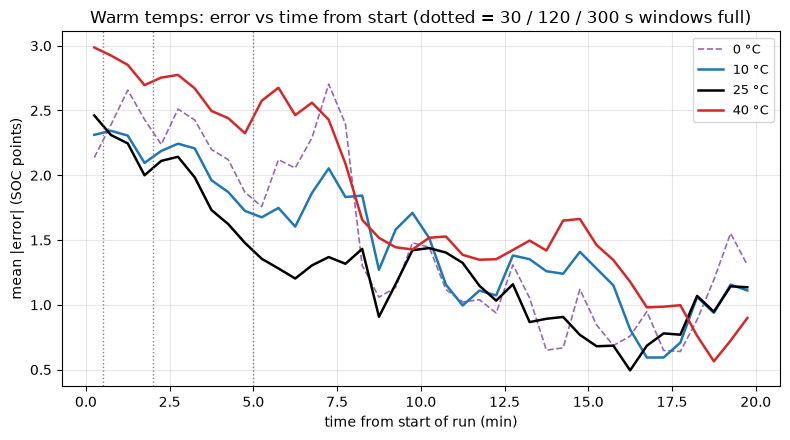

In [11]:
#warm error vs time, 30-s bins, first 20 min

BIN_MIN = 0.5
color_of = {0: "tab:purple", 10: "tab:blue", 25: "black", 40: "tab:red"}

fig, ax = plt.subplots(figsize=(8, 4.5))
for t in SEG_TEMPS:
    g = test[(test["ambient_c"] == t) & (test["segment"] != "rest tail") & (test["t_min"] < 20)]
    binned = g.groupby(g["t_min"].floordiv(BIN_MIN) * BIN_MIN)["abs_err"].mean()
    ax.plot(binned.index + BIN_MIN / 2, binned.values, color=color_of[t],
            lw=1.2 if t == 0 else 1.8, ls="--" if t == 0 else "-", label=f"{t} °C")
for w in [30, 120, 300]:
    ax.axvline(w / 60, color="grey", ls=":", lw=1)
ax.set_xlabel("time from start of run (min)")
ax.set_ylabel("mean |error| (SOC points)")
ax.set_title("Warm temps: error vs time from start (dotted = 30 / 120 / 300 s windows full)")
ax.grid(alpha=0.3)
ax.legend(fontsize=9)
fig.tight_layout()
fig.savefig(FIG_DIR / "warm_error_vs_time.png", dpi=150)
plt.show()

In [12]:
#MAE early vs later, warm temps

summary_rows = []
for t in SEG_TEMPS:
    g = test[(test["ambient_c"] == t) & (test["segment"] != "rest tail") & (test["t_min"] < 60)]
    a = g.loc[g["t_min"] < 5, "abs_err"].mean()
    b = g.loc[(g["t_min"] >= 5) & (g["t_min"] < 10), "abs_err"].mean()
    c = g.loc[g["t_min"] >= 10, "abs_err"].mean()
    summary_rows.append({"ambient_c": t, "MAE 0-5 min": a, "MAE 5-10 min": b, "MAE 10-60 min": c,
                         "ratio 0-5 / 10-60": a / c, "ratio 5-10 / 10-60": b / c})
early_vs_later = pd.DataFrame(summary_rows).set_index("ambient_c")
print(early_vs_later.round(3))

           MAE 0-5 min  MAE 5-10 min  MAE 10-60 min  ratio 0-5 / 10-60  \
ambient_c                                                                
0                2.298         1.830          1.331              1.727   
10               2.122         1.718          1.440              1.474   
25               2.009         1.275          1.379              1.457   
40               2.692         2.084          1.182              2.277   

           ratio 5-10 / 10-60  
ambient_c                      
0                       1.375  
10                      1.194  
25                      0.925  
40                      1.762  


Section 2: deep dive into 10 °C US06 (the worst warm run)

In [13]:
#find the US06 runs and the worst moment at 10 °C

def run_of(temp, cycle):
    ids = test.loc[(test["ambient_c"] == temp) & (test["cycle"] == cycle), "run_id"].unique()
    if len(ids) != 1:
        raise ValueError(f"Expected 1 {cycle} run at {temp}°C, found {len(ids)}: {list(ids)}")
    return ids[0]

us06 = {t: run_of(t, "US06") for t in sorted(test["ambient_c"].unique())}
print(f"{len(us06)} US06 runs:")
for t, rid in us06.items():
    print(f"  {t:>5} °C  {rid}")

g_all = test[test["run_id"] == us06[10]]
g = g_all[g_all["segment"] != "rest tail"]
worst = g.loc[g["abs_err"].idxmax()]

print("\nWorst moment, 10°C US06 (drive cycle):")
print(f"  time       {worst['time_s']:.0f} s ({worst['t_min']:.2f} min), segment = {worst['segment']}")
print(f"  SOC        true {worst['soc']*100:.2f}% pred {worst['soc_pred']*100:.2f}% "
      f"signed error {worst['err']:+.2f} pt")
print(f"  voltage    {worst['voltage']:.3f} V (300 s mean {worst['v_avg_300s']:.3f} V)")
print(f"  current    {worst['current']:.2f} A (300 s mean {worst['i_avg_300s']:.2f} A)")
print(f"  cell temp  {worst['temp_c']:.2f} °C")

6 US06 runs:
    -20 °C  n20degC_610_US06
    -10 °C  n10degC_601_US06
      0 °C  0degC_589_US06
     10 °C  10degC_567_US06
     25 °C  25degC_551_US06
     40 °C  40degC_556_US06

Worst moment, 10°C US06 (drive cycle):
  time       2502 s (41.70 min), segment = middle
  SOC        true 29.53% pred 22.51% signed error -7.02 pt
  voltage    3.509 V (300 s mean 3.462 V)
  current    5.43 A (300 s mean -2.09 A)
  cell temp  11.15 °C


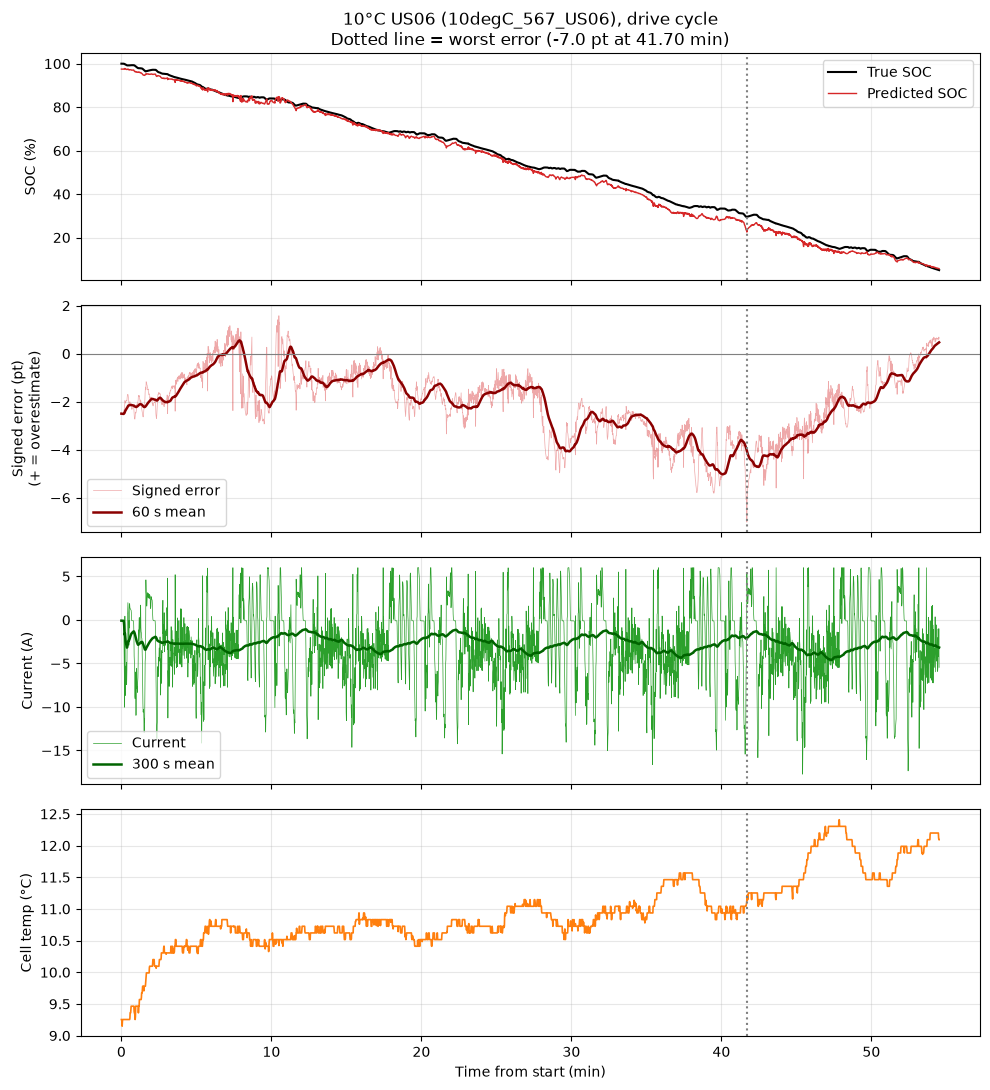

In [14]:
#10 °C US06, whole drive cycle, four panels

d = g.sort_values("time_s")
t_w = worst["t_min"]
smooth = d["err"].rolling(60, min_periods=1).mean()

fig, axes = plt.subplots(4, 1, figsize=(10, 11), sharex=True)

ax = axes[0]
ax.plot(d["t_min"], d["soc"] * 100, color="black", lw=1.5, label="True SOC")
ax.plot(d["t_min"], d["soc_pred"] * 100, color="tab:red", lw=1, label="Predicted SOC")
ax.set_ylabel("SOC (%)")
ax.legend(loc="upper right")

ax = axes[1]
ax.plot(d["t_min"], d["err"], color="tab:red", lw=0.5, alpha=0.4, label="Signed error")
ax.plot(d["t_min"], smooth, color="darkred", lw=1.8, label="60 s mean")
ax.axhline(0, color="gray", lw=0.8)
ax.set_ylabel("Signed error (pt)\n(+ = overestimate)")
ax.legend(loc="lower left")

ax = axes[2]
ax.plot(d["t_min"], d["current"], color="tab:green", lw=0.5, label="Current")
ax.plot(d["t_min"], d["i_avg_300s"], color="darkgreen", lw=1.8, label="300 s mean")
ax.set_ylabel("Current (A)")
ax.legend(loc="lower left")

ax = axes[3]
ax.plot(d["t_min"], d["temp_c"], color="tab:orange", lw=1.2)
ax.set_ylabel("Cell temp (°C)")
ax.set_xlabel("Time from start (min)")

for ax in axes:
    ax.axvline(t_w, color="gray", ls=":", lw=1.5)
    ax.grid(alpha=0.3)
axes[0].set_title(f"10°C US06 ({us06[10]}), drive cycle\n"
                  f"Dotted line = worst error ({worst['err']:+.1f} pt at {t_w:.2f} min)")
fig.tight_layout()
fig.savefig(FIG_DIR / "warm_deep_dive_10C_US06.png", dpi=150, bbox_inches="tight")
plt.show()

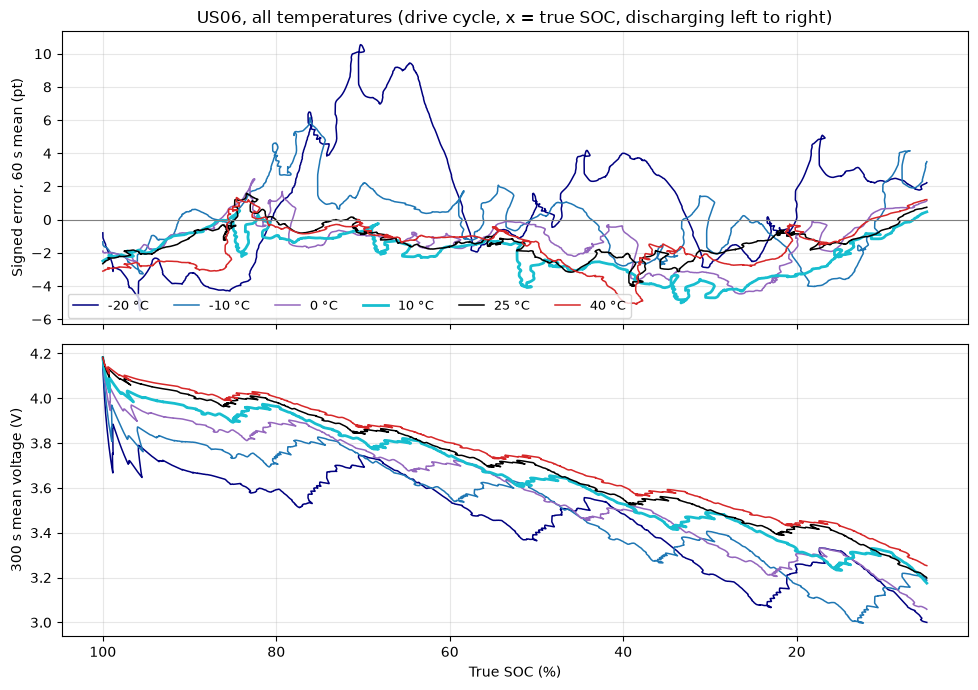

In [15]:
#US06 at every temperature: signed error and 300 s mean voltage vs true SOC

fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
temp_color = {-20: "navy", -10: "tab:blue", 0: "tab:purple", 10: "tab:cyan", 25: "black", 40: "tab:red"}
for t, rid in us06.items():
    r = test[(test["run_id"] == rid) & (test["segment"] != "rest tail")].sort_values("time_s")
    kw = dict(color=temp_color[t], lw=2 if t == 10 else 1.1, label=f"{t} °C")
    axes[0].plot(r["soc"] * 100, r["err"].rolling(60, min_periods=1).mean(), **kw)
    axes[1].plot(r["soc"] * 100, r["v_avg_300s"], **kw)

axes[0].axhline(0, color="gray", lw=0.8)
axes[0].set_ylabel("Signed error, 60 s mean (pt)")
axes[1].set_ylabel("300 s mean voltage (V)")
axes[1].set_xlabel("True SOC (%)")
axes[1].invert_xaxis()
for ax in axes:
    ax.grid(alpha=0.3)
axes[0].legend(ncol=6, fontsize=9, loc="lower left")
axes[0].set_title("US06, all temperatures (drive cycle, x = true SOC, discharging left to right)")
fig.tight_layout()
fig.savefig(FIG_DIR / "warm_us06_compare_temps.png", dpi=150, bbox_inches="tight")
plt.show()

In [16]:
#capacity check: does the model track SOC as if the cell had the training-session capacity?
#soc_alt = 1 + Ah / C_train, where C_train = row-weighted capacity of that temperature's training runs

train = splits["train"]
c_train = train.groupby("ambient_c")["capacity_ah"].mean()

rows = []
for rid, r in warm[warm["segment"] != "rest tail"].groupby("run_id"):
    t = r["ambient_c"].iloc[0]
    cap = r["capacity_ah"].iloc[0]
    soc_alt = 1 + r["ah"] / c_train[t]
    err_alt = (r["soc_pred"] - soc_alt) * 100
    rows.append({"run_id": rid, "ambient_c": t, "cycle": r["cycle"].iloc[0],
                 "cap_run": cap, "cap_train": c_train[t],
                 "cap diff %": 100 * (cap / c_train[t] - 1),
                 "rmse": np.sqrt((r["err"] ** 2).mean()),
                 "rmse with C_train": np.sqrt((err_alt ** 2).mean()),
                 "signed": r["err"].mean(),
                 "signed with C_train": err_alt.mean()})
cap_check = pd.DataFrame(rows).set_index("run_id").sort_values(["ambient_c", "cycle"])
print(cap_check.round(3).to_string())

                  ambient_c  cycle  cap_run  cap_train  cap diff %   rmse  rmse with C_train  signed  signed with C_train
run_id                                                                                                                   
10degC_576_HWFET         10  HWFET    2.547      2.528       0.720  1.135              1.053  -0.603               -0.273
10degC_582_LA92          10   LA92    2.542      2.528       0.546  1.244              1.189  -0.528               -0.279
10degC_576_UDDS          10   UDDS    2.547      2.528       0.720  1.333              1.461   0.406                0.738
10degC_567_US06          10   US06    2.610      2.528       3.232  2.498              1.486  -2.050               -0.558
25degC_551_LA92          25   LA92    2.727      2.703       0.884  1.254              1.086  -0.462               -0.055
25degC_551_UDDS          25   UDDS    2.726      2.703       0.878  1.741              1.449  -0.875               -0.476
25degC_551_US06         

In [17]:
#error vs load: mean |error| by 30 s mean current, warm temps, middle segment only

mid = warm[warm["segment"] == "middle"].copy()
mid["load_A"] = pd.cut(-mid["i_avg_30s"], [-np.inf, 0.5, 1.5, 3, 5, np.inf],
                       labels=["<0.5", "0.5-1.5", "1.5-3", "3-5", ">5"])
load = mid.pivot_table(index="load_A", columns="ambient_c", values="abs_err",
                       aggfunc="mean", observed=False).round(2)
share = (mid.pivot_table(index="load_A", columns="ambient_c", values="abs_err",
                         aggfunc="size", observed=False)
         / mid.groupby("ambient_c").size() * 100).round(1)
print("Mean |error| (pt) by 30 s mean discharge current (A):")
print(load.to_string())
print("\n% of middle-segment samples in each load band:")
print(share.to_string())

Mean |error| (pt) by 30 s mean discharge current (A):
ambient_c    10    25    40
load_A                     
<0.5       0.97  1.26  1.14
0.5-1.5    0.98  1.32  1.16
1.5-3      1.07  1.03  0.88
3-5        1.37  1.22  1.37
>5         2.00  1.24  1.80

% of middle-segment samples in each load band:
ambient_c    10    25    40
load_A                     
<0.5       37.7  43.2  38.2
0.5-1.5    31.3  33.3  31.6
1.5-3      21.1  13.7  21.1
3-5         8.0   7.8   7.6
>5          1.9   2.0   1.6


Section 3: does the tester limit the cell at warm temps? (same flags as the cold notebook)

In [18]:
#flag limit conditions on the active drive cycle (rest tail excluded); same definitions as cold notebook

V_OBS = 2.8
V_FLOOR_TOL = 0.01   # V: "at floor" = voltage <= 2.81 V
I_CAP_TOL = 0.05     # A: "at cap" = within 0.05 A of that temperature's maximum
FLAGS = ["at_vfloor", "at_icap", "at_rcap"]

active = test[test["segment"] != "rest tail"].copy()
active["at_vfloor"] = active["voltage"] <= V_OBS + V_FLOOR_TOL
max_dis = (-active["current"]).groupby(active["ambient_c"]).max()
max_reg = active["current"].groupby(active["ambient_c"]).max()
active["at_icap"] = -active["current"] >= active["ambient_c"].map(max_dis) - I_CAP_TOL
active["at_rcap"] = active["current"] >= active["ambient_c"].map(max_reg) - I_CAP_TOL

rows = []
for t, d in active[active["ambient_c"].isin(WARM)].groupby("ambient_c"):
    total_sq = (d["err"] ** 2).sum()
    any_limit = d[FLAGS].any(axis=1)
    row = {"temp_c": t,
           "max discharge (A)": -d["current"].min(),
           "max regen (A)": d["current"].max(),
           "% samples at any limit": 100 * any_limit.mean(),
           "share sq err at any limit (%)": 100 * (d.loc[any_limit, "err"] ** 2).sum() / total_sq}
    for f in FLAGS:
        row[f"% {f}"] = 100 * d[f].mean()
    rows.append(row)
print(pd.DataFrame(rows).set_index("temp_c").round(3).to_string())

        max discharge (A)  max regen (A)  % samples at any limit  share sq err at any limit (%)  % at_vfloor  % at_icap  % at_rcap
temp_c                                                                                                                            
10                 17.718          5.998                   0.541                          1.256        0.020      0.003      0.521
25                 17.444          5.998                   0.609                          0.572        0.004      0.004      0.605
40                 17.374          5.999                   0.513                          0.329        0.000      0.003      0.510


Section 4: is the warm bias a capacity mismatch, and is the start-up error tied to SOC or to time?

In [19]:
#capacity check, all 23 test runs: per-temperature summary (Section 2 table was warm runs only)

rows = []
for rid, r in test[test["segment"] != "rest tail"].groupby("run_id"):
    t = r["ambient_c"].iloc[0]
    err_alt = (r["soc_pred"] - (1 + r["ah"] / c_train[t])) * 100
    rows.append({"ambient_c": t, "cap diff %": 100 * (r["capacity_ah"].iloc[0] / c_train[t] - 1),
                 "rmse": np.sqrt((r["err"] ** 2).mean()),
                 "rmse with C_train": np.sqrt((err_alt ** 2).mean()),
                 "signed": r["err"].mean(),
                 "signed with C_train": err_alt.mean()})
cap_all = pd.DataFrame(rows).groupby("ambient_c").mean()
print("Mean over each temperature's test runs (drive cycle only):")
print(cap_all.round(3).to_string())

Mean over each temperature's test runs (drive cycle only):
           cap diff %   rmse  rmse with C_train  signed  signed with C_train
ambient_c                                                                   
-20             2.371  3.764              3.905  -0.777                0.340
-10             1.257  2.407              2.304  -0.611               -0.027
 0              0.616  1.605              1.565  -0.542               -0.259
 10             1.305  1.552              1.297  -0.694               -0.093
 25             0.880  1.569              1.320  -0.875               -0.475
 40             1.844  1.517              1.260  -0.958               -0.117


In [20]:
#signed error by true-SOC band, warm temps: test runs vs training runs (does the model under-predict near 100% everywhere?)

SOC_EDGES = [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 1.0001]
SOC_LABELS = ["0-10", "10-20", "20-30", "30-40", "40-50", "50-60", "60-70", "70-80", "80-90", "90-95", "95-100"]

tr = splits["train"]
tr = tr[tr["ambient_c"].isin(WARM)].copy()
tr["err"] = (predict(tr) - tr["soc"]) * 100

def by_soc(df, name):
    band = pd.cut(df["soc"], SOC_EDGES, labels=SOC_LABELS, right=False)
    return (df.groupby([band, "ambient_c"], observed=False)["err"].mean()
              .unstack().add_prefix(f"{name} ").round(2))

w_drive = warm[warm["segment"] != "rest tail"]
print("Mean signed error (pt) by true SOC band (%):")
print(pd.concat([by_soc(w_drive, "test"), by_soc(tr, "train")], axis=1).iloc[::-1].to_string())

Mean signed error (pt) by true SOC band (%):
ambient_c  test 10  test 25  test 40  train 10  train 25  train 40
soc                                                               
95-100       -2.21    -1.94    -2.67     -2.26     -2.07     -2.84
90-95        -1.30    -0.97    -1.89     -1.09     -0.56     -1.37
80-90         1.36     1.69     0.89      0.74      1.06      0.64
70-80         0.20    -0.12    -0.36      0.18     -0.26      0.22
60-70        -0.31    -0.71    -0.84     -0.10     -0.51     -0.02
50-60        -0.42    -1.04    -1.09      0.03     -0.59      0.39
40-50        -0.15    -0.82    -0.93      0.04     -0.62     -0.06
30-40        -0.73    -1.13    -0.72      0.06     -0.78      0.20
20-30        -0.76    -1.65    -1.83      0.09     -1.01     -0.22
10-20        -0.35    -2.26    -1.47      1.17     -0.96      0.92
0-10          0.63    -1.55    -1.02      0.66     -1.03      1.16


In [21]:
#start-up error: lined up by time or by SOC? per warm test run, signed error in time bands and in SOC bands

rows = []
for rid, r in w_drive.groupby("run_id"):
    row = {"run": f"{r['ambient_c'].iloc[0]} °C {r['cycle'].iloc[0]}"}
    for a, b in [(0, 4), (4, 8), (8, 12)]:
        row[f"t {a}-{b} min"] = r.loc[(r["t_min"] >= a) & (r["t_min"] < b), "err"].mean()
    for hi, lo in [(100, 95), (95, 90), (90, 85), (85, 80)]:
        row[f"SOC {hi}-{lo}%"] = r.loc[(r["soc"] * 100 < hi + 0.01) & (r["soc"] * 100 >= lo), "err"].mean()
    row["min to reach 90% SOC"] = r.loc[r["soc"] < 0.90, "t_min"].min()
    rows.append(row)
startup = pd.DataFrame(rows).set_index("run").sort_index()
print(startup.round(2).to_string())

tcols = [c for c in startup if c.startswith("t ")]
scols = [c for c in startup if c.startswith("SOC ")]
print("\nspread across runs (std of the band means): time bands",
      startup[tcols].std().round(2).tolist(), " SOC bands", startup[scols].std().round(2).tolist())

             t 0-4 min  t 4-8 min  t 8-12 min  SOC 100-95%  SOC 95-90%  SOC 90-85%  SOC 85-80%  min to reach 90% SOC
run                                                                                                                 
10 °C HWFET      -2.31      -1.77        0.03        -2.21       -1.63        0.16        0.99                  8.43
10 °C LA92       -2.37      -3.00       -1.77        -2.54       -1.96       -0.08        1.70                 14.57
10 °C UDDS       -2.26      -1.83       -1.91        -2.02       -0.98        1.86        3.36                 26.15
10 °C US06       -1.89      -0.23       -1.14        -2.04       -1.04       -0.06       -0.90                  5.28
25 °C LA92       -2.08      -1.61       -0.86        -1.88       -0.91        1.80        1.69                 15.08
25 °C UDDS       -2.26      -1.63       -1.93        -1.94       -0.93        2.13        2.06                 26.72
25 °C US06       -2.03      -0.83        0.31        -2.09      



spread across runs (std of the band means): time bands [0.34, 0.82, 1.08]  SOC bands [0.35, 0.54, 1.11, 1.08]


Conclusions (10, 25, 40 °C)

-Section 1: warm error is 1.1-2.5 pt RMSE per run. Every run under-predicts by ~2 pt at the start; it does not drop when the 300 s window fills, it lasts until ~8 min on average.
-Section 2: worst warm run is 10 °C US06 (-7.0 pt at 41.7 min). Its error builds through the middle of the run. Its cell capacity is 3.2% above the 10 °C training runs; relabelling with the training capacity cuts its RMSE from 2.50 to 1.49. Load only matters above 5 A (~2% of samples).
-Section 3: tester limits are negligible when warm (<0.6% of samples, <1.3% of squared error).
-Section 4: (a) every test session at every temperature has 0.6-2.4% more capacity than its training sessions, which explains most of the mid-run under-prediction (signed error at 40 °C -0.96 -> -0.12 pt). (b) the start-up error is tied to SOC, not time: all runs are -1.9 to -2.8 pt at 95-100% SOC, and training runs show the same, so the FNN cannot fit near-full charge.
-Rest tail: prediction drifts down 0.6-2.8 pt and settles at ~3.5% (true 5%), the opposite of the cold runs.

possible fixes: per-session capacity as an input or capacity-normalized labels; more weight / a different output layer near 100% SOC; check the same capacity effect in the cold results.